# Chapter 4: Opportunity Cost, Specialization, Scale, Scope, and Technology

This notebook reruns four worked examples from the chapter: short- and long-run labor demand (Le Chatelier), the market size that pays for specialization (Smith), comparative advantage, and the opportunity cost of time. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def ppf(ax, x_max, y_max, col="teal", text=None, style="solid", fill=False):
    """Linear production possibility frontier from (0, y_max) to (x_max, 0)."""
    ax.plot([0, x_max], [y_max, 0], color=color(col), linestyle=style, linewidth=2)
    if fill:
        ax.fill([0, x_max, 0], [0, 0, y_max], color=color(col), alpha=0.08)
    if text:
        label(ax, 0.55 * x_max, 0.45 * y_max, text, col=col, dx=6, dy=4)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def short_vs_long_run(q, w, r, K_fixed, A=10.0):
    """Labor needed for output q = A sqrt(L K) in the short run (K fixed) and the long run (K free).

    le-chatelier-principle: q = 5,400 so L K = 291,600. Short run with K = 270: L = 1,080.
    Long run at w = 15, r = 40: L = 540 sqrt(40/15) = 881.8, K = 540 sqrt(15/40) = 330.7.
    Returns LK, L_sr, K_sr, L_lr, K_lr, cost_sr, cost_lr.
    """
    LK = (q / A) ** 2
    L_sr = LK / K_fixed
    root = math.sqrt(LK)
    L_lr = root * math.sqrt(r / w)
    K_lr = root * math.sqrt(w / r)
    return {"LK": LK, "L_sr": L_sr, "K_sr": float(K_fixed), "L_lr": L_lr, "K_lr": K_lr,
            "cost_sr": w * L_sr + r * K_fixed, "cost_lr": w * L_lr + r * K_lr}


def fixed_vs_variable_threshold(F, c_low, c_high, q, friction=0.0):
    """Specialized method (setup F, unit cost c_low + friction) against a general method (unit cost c_high).

    smith-extent-of-the-market-theorem: F = 24,000, c_low = 30, c_high = 90 gives a break-even
    of 24,000 / (90 - 30) = 400 units without friction. At q = 750 with delivery 3:
    specialized 24,000 + 33 x 750 = 48,750 against general 67,500. Adding a 35 delay
    (friction 38): specialized 75,000, a 7,500 loss. Returns general, specialized, saving
    (general - specialized), threshold (None when specialization can never pay).
    """
    general = c_high * q
    specialized = F + (c_low + friction) * q
    gap = c_high - c_low - friction
    threshold = F / gap if gap > 0 else None
    return {"general": general, "specialized": specialized, "saving": general - specialized,
            "threshold": threshold}


def comparative_advantage(hours_A, hours_B, labor, tot, export, autarky=None):
    """Two regions, two goods (cloth, wine), labor only; A specializes in cloth and B in wine.

    comparative-advantage (chapter 4): hours per unit A = (2, 4), B = (6, 8); labor (48, 96).
    Opportunity costs of cloth: A 2/4 = 0.5 wine, B 6/8 = 0.75 wine. Specialized output: A 24
    cloth, B 12 wine. At tot = 0.625 wine per cloth with 8 cloth exported: A (16, 5), B (8, 7);
    hours to make those bundles alone: 52 and 104.
    ``autarky`` is ((C_A, W_A), (C_B, W_B)) for the before-trade bundles; the book uses
    ((16, 4), (8, 6)). Returns a dict with oc_cloth_A/B, output_A (cloth), output_B (wine),
    post_A, post_B, hours_alone_A/B, gain_A/B (wine gained at unchanged cloth, when autarky given),
    and in_range (tot between the two opportunity costs, inclusive).
    """
    (cA, wA), (cB, wB) = hours_A, hours_B
    LA, LB = labor
    oc_A, oc_B = cA / wA, cB / wB
    out_A, out_B = LA / cA, LB / wB
    post_A = (out_A - export, tot * export)
    post_B = (export, out_B - tot * export)
    res = {"oc_cloth_A": oc_A, "oc_cloth_B": oc_B, "output_A": out_A, "output_B": out_B,
           "post_A": post_A, "post_B": post_B,
           "hours_alone_A": cA * post_A[0] + wA * post_A[1], "hours_alone_B": cB * post_B[0] + wB * post_B[1],
           "in_range": min(oc_A, oc_B) <= tot <= max(oc_A, oc_B)}
    if autarky is not None:
        (aCA, aWA), (aCB, aWB) = autarky
        res["gain_A"] = (post_A[0] - aCA, post_A[1] - aWA)
        res["gain_B"] = (post_B[0] - aCB, post_B[1] - aWB)
    return res


def full_cost_compare(cash, hours, v):
    """Full cost of each option = cash + hours x v, and the break-even value of time for two options.

    opportunity-cost: home (18, 1.5) and prepared (42, 0.25). At v = 30: 63 and 49.50; break-even
    v* = (42 - 18)/(1.5 - 0.25) = 19.20.
    """
    costs = [c + h * v for c, h in zip(cash, hours)]
    breakeven = None
    if len(cash) == 2 and hours[0] != hours[1]:
        breakeven = (cash[1] - cash[0]) / (hours[0] - hours[1])
    return {"costs": costs, "breakeven": breakeven}


plt.rcParams.update(HOUSE_RC)


production = SimpleNamespace(short_vs_long_run=short_vs_long_run, fixed_vs_variable_threshold=fixed_vs_variable_threshold)


trade = SimpleNamespace(comparative_advantage=comparative_advantage)


choice = SimpleNamespace(full_cost_compare=full_cost_compare)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'le-chatelier-principle': {'q': 5400,
                            'w0': 10,
                            'w': 15,
                            'r': 40,
                            'LK': 291600,
                            'L0': 1080,
                            'K0': 270,
                            'L_sr': 1080,
                            'L_lr': 882,
                            'K_lr': 331,
                            'labor_cut': 198},
 'smith-extent-of-the-market-theorem': {'F': 24000,
                                        'c_general': 90,
                                        'c_special': 30,
                                        'threshold': 400,
                                        'q_small': 250,
                                        'general_small': 22500,
                                        'special_small': 31500,
                                        'q': 750,
                                        'delivery': 3,
                                        'special': 48750,
                                        'general': 67500,
                                        'saving': 18750,
                                        'delay': 35,
                                        'special_delay': 75000,
                                        'loss_delay': 7500},
 'comparative-advantage': {'hours_A': (2, 4),
                           'hours_B': (6, 8),
                           'labor': (48, 96),
                           'oc_A': 0.5,
                           'oc_B': 0.75,
                           'autarky_A': (16, 4),
                           'autarky_B': (8, 6),
                           'out_A': 24,
                           'out_B': 12,
                           'tot': 0.625,
                           'export': 8,
                           'post_A': (16, 5),
                           'post_B': (8, 7),
                           'hours_alone_A': 52,
                           'hours_alone_B': 104},
 'opportunity-cost': {'cash': (18, 42),
                      'hours': (1.5, 0.25),
                      'breakeven': 19.2,
                      'v': 30,
                      'fc_home': 63,
                      'fc_prepared': 49.5,
                      'v2': 12,
                      'fc_home2': 36,
                      'fc_prepared2': 45},
 'constructed': {'le-chatelier-principle': {'w': [20, 25]},
                 'smith-extent-of-the-market-theorem': {'q': [1000], 'friction': [0]},
                 'comparative-advantage': {'export': [4, 12]},
                 'opportunity-cost': {'v': [45]}}}


def lechatelier_picture(w=15, run="long"):
    r, q, K0 = 40, 5_400, 270
    res = production.short_vs_long_run(q, w, r, K0)
    L, K = (res["L_lr"], res["K_lr"]) if run == "long" else (res["L_sr"], res["K_sr"])
    cost = w * L + r * K
    Ls = np.linspace(300, 2_100, 300)
    fig, ax = new_figure()
    ax.plot(Ls, res["LK"] / Ls, color=PALETTE["teal"], linewidth=2.2, label="isoquant: 5,400 kits (LK = 291,600)")
    ax.plot([0, cost / w], [cost / r, 0], color=PALETTE["ink"], linestyle="dashed", linewidth=1.5,
            label=f"isocost at w = {w}: {num(cost, 0)}")
    ax.axhline(K0, color=PALETTE["grey"], linewidth=1, linestyle="dotted", label="installed machines K = 270")
    mark(ax, 1_080, 270, "start (1,080, 270)", col="gold", dx=8, dy=8, va="bottom")
    if abs(L - 1_080) > 0.5:
        mark(ax, L, K, f"({num(L, 0)}, {num(K, 0)})", col="navy", dx=-8, dy=8, ha="right")
    ax.set_xlim(300, 2_100)
    ax.set_ylim(100, 900)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Labor hours L")
    ax.set_ylabel("Machine hours K")
    cut = 1_080 - L
    metrics = {"Labor hours": num(L, 0), "Machine hours": num(K, 0), "Labor change from 1,080": num(-cut, 0),
               "Cost at the new wage": num(cost, 0), "Horizon": "long run" if run == "long" else "short run, K fixed"}
    if run == "long":
        interp = (f"With both inputs free, {w}L = 40K and LK = 291,600 give L = 540 x sqrt(40/{w}) = {num(L, 0)} and "
                  f"K = 540 x sqrt({w}/40) = {num(K, 0)}. "
                  + ("At the original wage labor is unchanged: 1,080 - 1,080 = 0 hours." if abs(cut) < 0.5 else
                     f"Labor falls by 1,080 - {num(L, 0)} = {num(cut, 0)} hours.")
                  + f" Since {w}L = 40K, cost is 2 x 40 x K = 80 x {num(K, 3)} = {num(cost, 0)}.")
        steps = [f"Tangency: {w}L = 40K", "Isoquant: LK = 291,600, so sqrt(LK) = 540",
                 f"L = 540 x sqrt(40/{w}) = {num(L, 0)}", f"K = 540 x sqrt({w}/40) = {num(K, 0)}",
                 f"Labor change = {num(L, 0)} - 1,080 = {num(-cut, 0)}",
                 f"Cost = {w}L + 40K = 80 x {num(K, 3)} = {num(cost, 0)}"]
    else:
        interp = (f"With machines fixed at 270, L = 291,600 / 270 = 1,080 whatever the wage; at w = {w} cost is "
                  f"{w} x 1,080 + 40 x 270 = {num(cost, 0)}. The short-run labor response is zero.")
        steps = ["K stays at 270", "L = 291,600 / 270 = 1,080",
                 f"Cost = {w} x 1,080 + 40 x 270 = {num(cost, 0)}"]
    alt = (f"Isoquant for 5,400 kits with the starting point (1,080, 270) and the {run}-run choice at wage {w}: "
           f"{num(L, 0)} labor hours and {num(K, 0)} machine hours.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def smith_picture(q=750, friction=3):
    res = production.fixed_vs_variable_threshold(24_000, 30, 90, q, friction)
    qs = np.linspace(0, 1_100, 200)
    fig, ax = new_figure()
    ax.plot(qs, 90 * qs, color=PALETTE["navy"], linewidth=2.2, label=r"general: \$90 per unit")
    ax.plot(qs, 24_000 + (30 + friction) * qs, color=PALETTE["teal"], linewidth=2.2,
            label=f"specialized: \\$24,000 + \\${30 + friction} per unit")
    if res["threshold"] is not None and res["threshold"] <= 1_100:
        vline(ax, res["threshold"], f"break-even {num(res['threshold'], 0)}", col="grey", ha="right", y_frac=0.12)
    mark(ax, q, res["general"], col="navy")
    mark(ax, q, res["specialized"], col="teal")
    ax.set_xlim(0, 1_100)
    ax.set_ylim(0, 110_000)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Accessible sales (devices)")
    ax.set_ylabel("Total cost ($)")
    winner, tie = tie_or_winner("specialized", -res["specialized"], "general", -res["general"])
    verdict = ("The two methods tie exactly." if tie else
               f"Specialization saves {money(res['saving'], 0)}." if winner == "specialized" else
               f"Specialization loses {money(-res['saving'], 0)}.")
    thr = (f"{num(res['threshold'], 1)} devices" if res["threshold"] is not None else "none")
    metrics = {"General cost": money(res["general"], 0), "Specialized cost": money(res["specialized"], 0),
               "Saving from specializing": money(res["saving"], 0), "Break-even sales": thr,
               "Choice": "tie" if tie else winner}
    interp = (f"Specialized: 24,000 + (30 + {friction}) x {num(q, 0)} = {num(res['specialized'], 0)}. General: 90 x "
              f"{num(q, 0)} = {num(res['general'], 0)}. {verdict} Break-even sales are 24,000 / (90 - 30 - {friction}) = "
              f"{thr}.")
    steps = [f"Specialized = 24,000 + {30 + friction} x {num(q, 0)} = {num(res['specialized'], 0)}",
             f"General = 90 x {num(q, 0)} = {num(res['general'], 0)}",
             f"Difference = {num(res['general'], 0)} - {num(res['specialized'], 0)} = {num(res['saving'], 0)}",
             f"Break-even = 24,000 / {90 - 30 - friction} = {thr}"]
    alt = (f"Total cost lines for the general and specialized methods with an extra cost of {friction} per unit. At "
           f"{num(q, 0)} devices they cost {num(res['general'], 0)} and {num(res['specialized'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def trade_picture(tot=0.625, x=8):
    res = trade.comparative_advantage((2, 4), (6, 8), (48, 96), tot, x, autarky=((16, 4), (8, 6)))
    fig, (axA, axB) = new_figure(ncols=2)
    for ax, cmax, wmax, aut, post, name, hours, lab in [
            (axA, 24, 12, (16, 4), res["post_A"], "Region A", res["hours_alone_A"], 48),
            (axB, 16, 12, (8, 6), res["post_B"], "Region B", res["hours_alone_B"], 96)]:
        ppf(ax, cmax, wmax, col="teal", fill=True)
        mark(ax, aut[0], aut[1], f"before ({num(aut[0], 0)}, {num(aut[1], 0)})", col="gold", dx=-8, dy=-12,
             ha="right", va="top")
        mark(ax, post[0], post[1], f"after ({num(post[0], 0)}, {num(post[1], 2)})", col="navy", dx=8, dy=8)
        ax.set_xlim(0, 30)
        ax.set_ylim(0, 13.5)
        ax.set_title(f"{name}: {num(lab, 0)} hours", fontsize=11.5)
        ax.set_xlabel("Cloth")
        ax.set_ylabel("Wine")
    (cA, wA), (cB, wB) = res["post_A"], res["post_B"]

    def where(h, lab):
        return "beyond its frontier" if h > lab + 1e-9 else ("on its frontier" if abs(h - lab) <= 1e-9 else "inside its frontier")
    metrics = {"A consumes (cloth, wine)": f"({num(cA, 0)}, {num(wA, 2)})", "B consumes (cloth, wine)": f"({num(cB, 0)}, {num(wB, 2)})",
               "Hours A would need alone": num(res["hours_alone_A"], 1), "Hours B would need alone": num(res["hours_alone_B"], 1),
               "Price within 0.5 to 0.75": "yes" if res["in_range"] else "no"}
    interp = (f"A makes 48 / 2 = 24 cloth and B makes 96 / 8 = 12 wine. A sends {x} cloth for {num(tot, 3)} x {x} = "
              f"{num(wA, 2)} wine, keeping {num(cA, 0)} cloth; B keeps 12 - {num(wA, 2)} = {num(wB, 2)} wine. A's bundle "
              f"would take 2 x {num(cA, 0)} + 4 x {num(wA, 2)} = {num(res['hours_alone_A'], 1)} hours alone, "
              f"{where(res['hours_alone_A'], 48)}; B's would take 6 x {num(cB, 0)} + 8 x {num(wB, 2)} = "
              f"{num(res['hours_alone_B'], 1)} hours, {where(res['hours_alone_B'], 96)}.")
    steps = [f"A: cloth 24 - {x} = {num(cA, 0)}, wine {num(tot, 3)} x {x} = {num(wA, 2)}",
             f"B: cloth {x}, wine 12 - {num(wA, 2)} = {num(wB, 2)}",
             f"A alone: 2 x {num(cA, 0)} + 4 x {num(wA, 2)} = {num(res['hours_alone_A'], 1)} hours (has 48)",
             f"B alone: 6 x {x} + 8 x {num(wB, 2)} = {num(res['hours_alone_B'], 1)} hours (has 96)"]
    alt = (f"Two production possibility frontiers. Region A moves from (16, 4) to ({num(cA, 0)}, {num(wA, 2)}) and region "
           f"B from (8, 6) to ({num(cB, 0)}, {num(wB, 2)}) at {num(tot, 3)} wine per cloth.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cook_picture(v=30):
    res = choice.full_cost_compare((18, 42), (1.5, 0.25), v)
    home, prep = res["costs"]
    vs = np.linspace(0, 50, 200)
    fig, ax = new_figure()
    ax.plot(vs, 18 + 1.5 * vs, color=PALETTE["teal"], linewidth=2.2, label="cook at home: 18 + 1.5v")
    ax.plot(vs, 42 + 0.25 * vs, color=PALETTE["gold"], linewidth=2.2, label="buy prepared: 42 + 0.25v")
    vline(ax, res["breakeven"], f"v* = {num(res['breakeven'])}", col="grey", ha="left", y_frac=0.12)
    mark(ax, v, home, col="teal")
    mark(ax, v, prep, col="gold")
    ax.set_xlim(0, 50)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Value of an hour v ($)")
    ax.set_ylabel("Full cost of the meals ($)")
    winner, tie = tie_or_winner("cook", -home, "buy", -prep)
    verdict = ("The two options tie exactly at the break-even value." if tie else
               "Cooking is cheaper in full terms." if winner == "cook" else "Buying is cheaper in full terms.")
    metrics = {"Full cost, cook": money(home), "Full cost, buy": money(prep), "Break-even value of time": money(res["breakeven"]),
               "Choice": "tie" if tie else winner, "Difference": money(abs(home - prep))}
    interp = (f"Cook: 18 + 1.5 x {num(v)} = {num(home)}. Buy: 42 + 0.25 x {num(v)} = {num(prep)}. {verdict} The "
              f"break-even is (42 - 18) / (1.5 - 0.25) = 24 / 1.25 = {num(res['breakeven'])} per hour.")
    steps = [f"Cook = 18 + 1.5 x {num(v)} = {num(home)}", f"Buy = 42 + 0.25 x {num(v)} = {num(prep)}",
             f"v* = 24 / 1.25 = {num(res['breakeven'])}", "Choice: " + ("tie" if tie else winner)]
    alt = (f"Full cost lines for cooking and buying against the value of an hour, crossing at 19.20. At v = {num(v)} "
           f"cooking costs {num(home)} and buying {num(prep)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Le Chatelier principle: short run vs long run

Output $q=10\sqrt{LK}$ is fixed at 5,400, so $LK=291{,}600$; $r=40$ and the wage rises from 10.

$$L_{SR}=\frac{291{,}600}{270}=1{,}080, \qquad L_{LR}=540\sqrt{\frac{40}{15}}\approx882$$

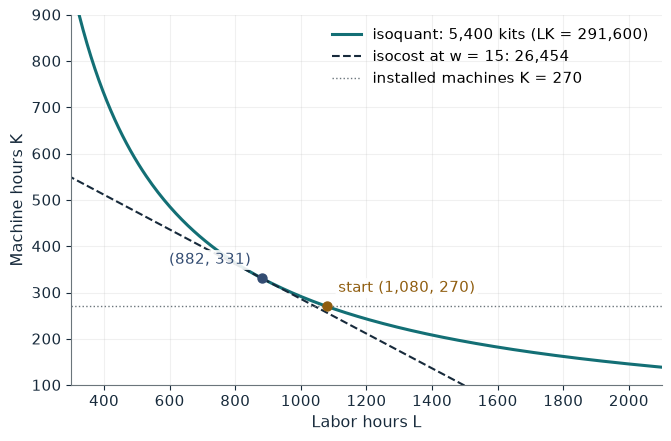

Labor hours              882
Machine hours            331
Labor change from 1,080  -198
Cost at the new wage     26,454
Horizon                  long run

Worked steps:
  1. Tangency: 15L = 40K
  2. Isoquant: LK = 291,600, so sqrt(LK) = 540
  3. L = 540 x sqrt(40/15) = 882
  4. K = 540 x sqrt(15/40) = 331
  5. Labor change = 882 - 1,080 = -198
  6. Cost = 15L + 40K = 80 x 330.681 = 26,454

With both inputs free, 15L = 40K and LK = 291,600 give L = 540 x sqrt(40/15) = 882 and K = 540 x sqrt(15/40) = 331. Labor falls by 1,080 - 882 = 198 hours. Since 15L = 40K, cost is 2 x 40 x K = 80 x 330.681 = 26,454.


In [2]:
show(lechatelier_picture(w=15, run='long'))

Change one input, `w`, and hold the others at the book's values:

In [3]:
sweep(lechatelier_picture, 'w', [10, 15, 20, 25], {'run': 'long'}, ['Labor hours', 'Machine hours', 'Labor change from 1,080'])

w | Labor hours | Machine hours | Labor change from 1,080
10 | 1,080 | 270 | 0
15 | 882 | 331 | -198
20 | 764 | 382 | -316
25 | 683 | 427 | -397


With machines fixed, labor stays at 1,080 at every wage. Once machines adjust, a wage of 15 cuts labor to 882 hours, 198 fewer.

## 2. Smith extent-of-the-market theorem

General production costs \$90 per unit; specialization costs \$30 per unit after \$24,000 of setup.

$$q^*=\frac{\$24{,}000}{\$90-\$30}=400\text{ devices}$$

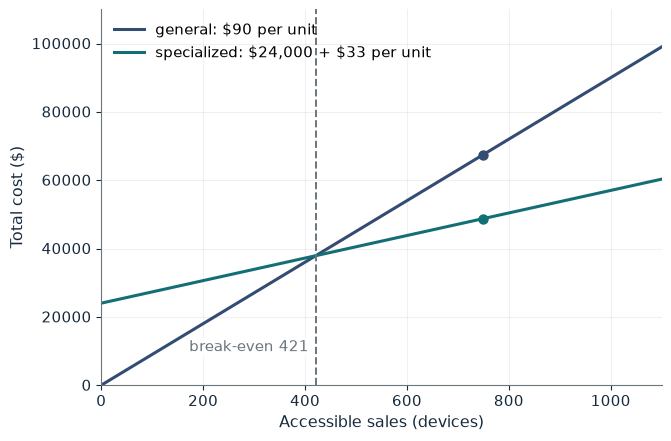

General cost              $67,500
Specialized cost          $48,750
Saving from specializing  $18,750
Break-even sales          421.1 devices
Choice                    specialized

Worked steps:
  1. Specialized = 24,000 + 33 x 750 = 48,750
  2. General = 90 x 750 = 67,500
  3. Difference = 67,500 - 48,750 = 18,750
  4. Break-even = 24,000 / 57 = 421.1 devices

Specialized: 24,000 + (30 + 3) x 750 = 48,750. General: 90 x 750 = 67,500. Specialization saves $18,750. Break-even sales are 24,000 / (90 - 30 - 3) = 421.1 devices.


In [4]:
show(smith_picture(q=750, friction=3))

Change one input, `friction`, and hold the others at the book's values:

In [5]:
sweep(smith_picture, 'friction', [0, 3, 38], {'q': 750}, ['Specialized cost', 'Saving from specializing', 'Break-even sales'])

friction | Specialized cost | Saving from specializing | Break-even sales
0 | $46,500 | $21,000 | 400.0 devices
3 | $48,750 | $18,750 | 421.1 devices
38 | $75,000 | -$7,500 | 1,090.9 devices


At 750 sales with \$3 delivery, specialization costs \$48,750 against \$67,500 and saves \$18,750. A \$35 border delay on top raises it to \$75,000, a \$7,500 loss.

## 3. Division of labor and comparative advantage

Region A: 2 hours per cloth, 4 per wine, 48 hours. Region B: 6 and 8, 96 hours. $OC_A(C)=2/4=0.5W$ and $OC_B(C)=6/8=0.75W$.

$$(C_A,W_A)=(16,5),\qquad (C_B,W_B)=(8,7)$$

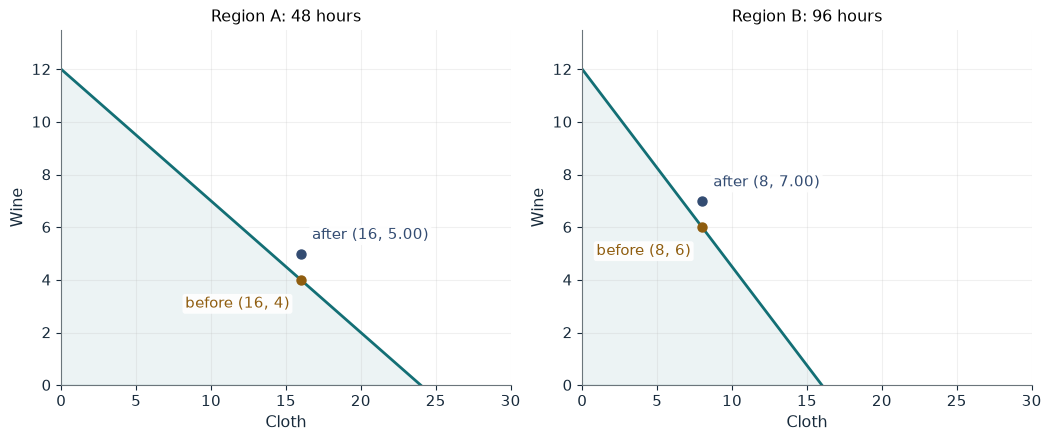

A consumes (cloth, wine)  (16, 5.00)
B consumes (cloth, wine)  (8, 7.00)
Hours A would need alone  52.0
Hours B would need alone  104.0
Price within 0.5 to 0.75  yes

Worked steps:
  1. A: cloth 24 - 8 = 16, wine 0.625 x 8 = 5.00
  2. B: cloth 8, wine 12 - 5.00 = 7.00
  3. A alone: 2 x 16 + 4 x 5.00 = 52.0 hours (has 48)
  4. B alone: 6 x 8 + 8 x 7.00 = 104.0 hours (has 96)

A makes 48 / 2 = 24 cloth and B makes 96 / 8 = 12 wine. A sends 8 cloth for 0.625 x 8 = 5.00 wine, keeping 16 cloth; B keeps 12 - 5.00 = 7.00 wine. A's bundle would take 2 x 16 + 4 x 5.00 = 52.0 hours alone, beyond its frontier; B's would take 6 x 8 + 8 x 7.00 = 104.0 hours, beyond its frontier.


In [6]:
show(trade_picture(tot=0.625, x=8))

Change one input, `tot`, and hold the others at the book's values:

In [7]:
sweep(trade_picture, 'tot', [0.5, 0.625, 0.75], {'x': 8}, ['A consumes (cloth, wine)', 'B consumes (cloth, wine)', 'Hours A would need alone', 'Hours B would need alone'])

tot | A consumes (cloth, wine) | B consumes (cloth, wine) | Hours A would need alone | Hours B would need alone
0.5 | (16, 4.00) | (8, 8.00) | 48.0 | 112.0
0.625 | (16, 5.00) | (8, 7.00) | 52.0 | 104.0
0.75 | (16, 6.00) | (8, 6.00) | 56.0 | 96.0


At 0.625 wine per cloth each region gains one wine; A's bundle would take 52 hours alone and B's 104. At the edge prices one region captures the whole gain.

## 4. Opportunity cost and household production

$$FC_H=\$18+1.5v,\qquad FC_P=\$42+0.25v, \qquad v^*=\frac{\$42-\$18}{1.5-0.25}=\$19.20$$

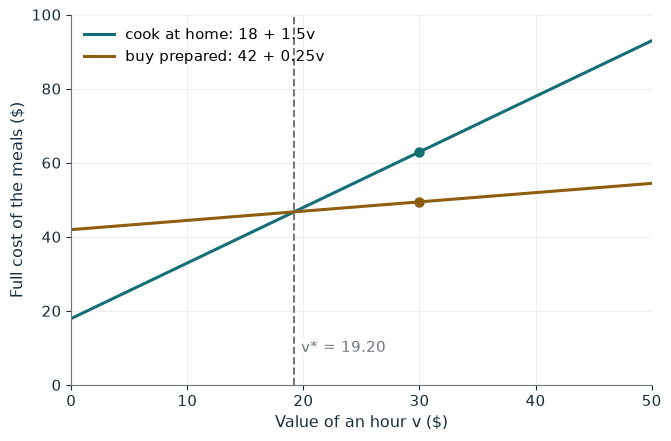

Full cost, cook           $63.00
Full cost, buy            $49.50
Break-even value of time  $19.20
Choice                    buy
Difference                $13.50

Worked steps:
  1. Cook = 18 + 1.5 x 30.00 = 63.00
  2. Buy = 42 + 0.25 x 30.00 = 49.50
  3. v* = 24 / 1.25 = 19.20
  4. Choice: buy

Cook: 18 + 1.5 x 30.00 = 63.00. Buy: 42 + 0.25 x 30.00 = 49.50. Buying is cheaper in full terms. The break-even is (42 - 18) / (1.5 - 0.25) = 24 / 1.25 = 19.20 per hour.


In [8]:
show(cook_picture(v=30))

Change one input, `v`, and hold the others at the book's values:

In [9]:
sweep(cook_picture, 'v', [12, 19.2, 30, 45], {}, ['Full cost, cook', 'Full cost, buy', 'Choice'])

v | Full cost, cook | Full cost, buy | Choice
12 | $36.00 | $45.00 | cook
19.2 | $46.80 | $46.80 | tie
30 | $63.00 | $49.50 | buy
45 | $85.50 | $53.25 | buy


At \$30 an hour cooking costs \$63 and buying \$49.50, so buying wins; at \$12 cooking costs \$36 against \$45. At exactly \$19.20 the two tie.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

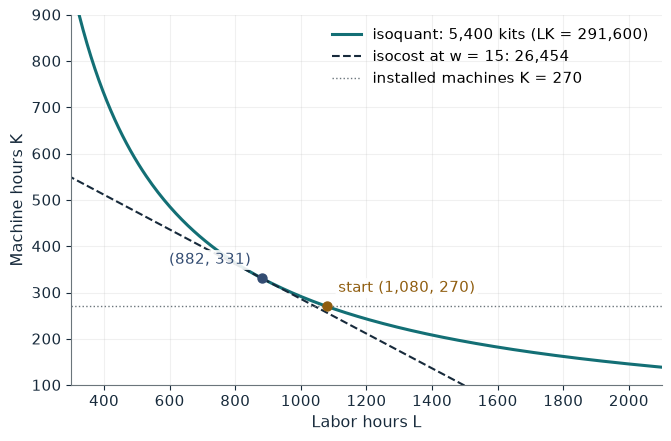

Labor hours              882
Machine hours            331
Labor change from 1,080  -198
Cost at the new wage     26,454
Horizon                  long run

Worked steps:
  1. Tangency: 15L = 40K
  2. Isoquant: LK = 291,600, so sqrt(LK) = 540
  3. L = 540 x sqrt(40/15) = 882
  4. K = 540 x sqrt(15/40) = 331
  5. Labor change = 882 - 1,080 = -198
  6. Cost = 15L + 40K = 80 x 330.681 = 26,454

With both inputs free, 15L = 40K and LK = 291,600 give L = 540 x sqrt(40/15) = 882 and K = 540 x sqrt(15/40) = 331. Labor falls by 1,080 - 882 = 198 hours. Since 15L = 40K, cost is 2 x 40 x K = 80 x 330.681 = 26,454.


In [10]:
show(lechatelier_picture(w=15, run='long'))

## Practice

**1.** With the wage at 25, what is long-run labor?

<details><summary>Answer</summary>

L = 540 x sqrt(40/25) = 540 x 1.265 = 683 hours.

</details>

**2.** With 1,000 sales and only the \$3 delivery cost, which method wins and by how much?

<details><summary>Answer</summary>

Specialized 24,000 + 33 x 1,000 = 57,000 against 90,000: specialization saves 33,000.

</details>

**3.** At 0.75 wine per cloth and 8 cloth exported, what does each region consume?

<details><summary>Answer</summary>

A: 16 cloth and 6 wine; B: 8 cloth and 6 wine. B gains nothing; A gains 2 wine.

</details>